# Modèle de risque de crédit : probabilité de défaut, notation et perte attendue

Objectif : construire un modèle de probabilité de défaut (PD) sur 30 000 clients de cartes de crédit,
le transformer en échelle de notation, calculer la perte attendue et les fonds propres réglementaires (IRB),
puis mesurer l'impact d'un scénario macroéconomique adverse.

## 1. Données et exploration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
fichier = "data/credit_taiwan.csv"

if not os.path.exists(fichier):
    # Premier lancement : téléchargement depuis le dépôt UCI, puis sauvegarde locale
    from ucimlrepo import fetch_ucirepo
    credit = fetch_ucirepo(id=350)
    X = credit.data.features.copy()
    y = credit.data.targets.iloc[:, 0]
    X.columns = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
                 + [f"PAY_{i}" for i in range(1, 7)]       # statut de paiement, du mois le plus récent (1) au plus ancien (6)
                 + [f"BILL_AMT{i}" for i in range(1, 7)]   # montant facturé
                 + [f"PAY_AMT{i}" for i in range(1, 7)])   # montant remboursé
    X.assign(defaut=y.values).to_csv(fichier, index=False)

df = pd.read_csv(fichier)
print(f"{df.shape[0]} clients, {df.shape[1] - 1} variables")
print(f"Taux de défaut : {df['defaut'].mean():.2%}")
df.head()

30000 clients, 23 variables
Taux de défaut : 22.12%


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,defaut
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
# PAY_1 : statut de paiement du mois le plus récent
# -2 / -1 / 0 = pas de retard ; 1 = un mois de retard ; 2 = deux mois de retard ; etc.
taux_pay = (df.groupby("PAY_1")["defaut"].agg(["count", "mean"])
              .rename(columns={"count": "Clients", "mean": "Taux de défaut"}))
taux_pay.style.format({"Taux de défaut": "{:.1%}"})

,Clients,Taux de défaut
PAY_1,,
-2,2759,13.2%
-1,5686,16.8%
0,14737,12.8%
1,3688,33.9%
2,2667,69.1%
3,322,75.8%
4,76,68.4%
5,26,50.0%
6,11,54.5%


In [4]:
df["tranche_plafond"] = pd.qcut(df["LIMIT_BAL"], 5, labels=["Q1 (bas)", "Q2", "Q3", "Q4", "Q5 (haut)"])
df["tranche_age"] = pd.cut(df["AGE"], bins=[20, 30, 40, 50, 60, 80])

print(df.groupby("tranche_plafond", observed=True)["defaut"].mean().map("{:.1%}".format))
print(df.groupby("tranche_age", observed=True)["defaut"].mean().map("{:.1%}".format))

tranche_plafond
Q1 (bas)     31.8%
Q2           25.8%
Q3           19.9%
Q4           16.9%
Q5 (haut)    13.8%
Name: defaut, dtype: object
tranche_age
(20, 30]    22.4%
(30, 40]    20.4%
(40, 50]    23.3%
(50, 60]    25.2%
(60, 80]    26.8%
Name: defaut, dtype: object


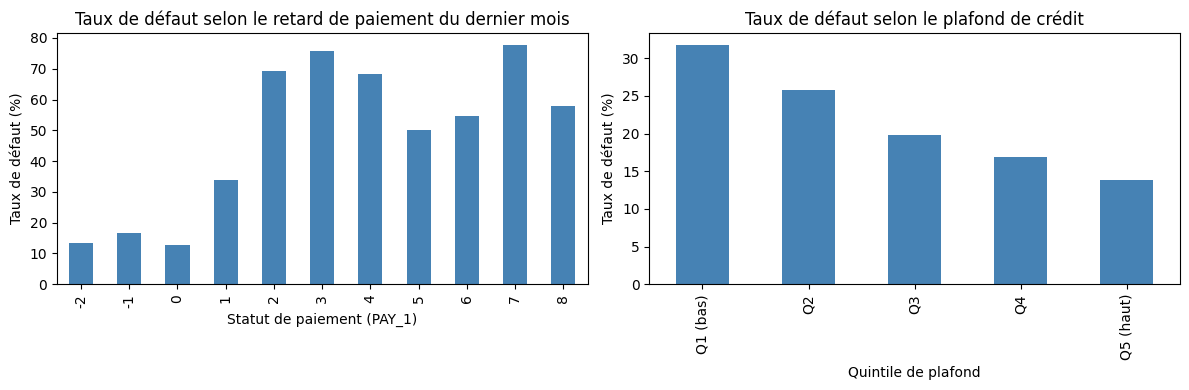

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(taux_pay["Taux de défaut"] * 100).plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Taux de défaut selon le retard de paiement du dernier mois")
axes[0].set_xlabel("Statut de paiement (PAY_1)")
axes[0].set_ylabel("Taux de défaut (%)")

(df.groupby("tranche_plafond", observed=True)["defaut"].mean() * 100).plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("Taux de défaut selon le plafond de crédit")
axes[1].set_xlabel("Quintile de plafond")
axes[1].set_ylabel("Taux de défaut (%)")

plt.tight_layout()
plt.savefig("figures/exploration.png", dpi=150, bbox_inches="tight")
plt.show()

df = df.drop(columns=["tranche_plafond", "tranche_age"])   # colonnes temporaires

## 2. Préparation des variables : découpage en classes, WoE et IV

In [6]:
# Nettoyage : codes non documentés regroupés dans « autre »
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})   # 4 = autre
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})                 # 3 = autre

# Nouvelles variables construites à partir de l'historique
pay_cols = [f"PAY_{i}" for i in range(1, 7)]
df["retard_max_6m"] = df[pay_cols].max(axis=1).clip(lower=0)     # pire retard sur 6 mois
df["nb_mois_retard"] = (df[pay_cols] >= 1).sum(axis=1)           # nombre de mois avec un retard
df["taux_utilisation"] = df["BILL_AMT1"] / df["LIMIT_BAL"]       # part du plafond utilisée

In [7]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.3, stratify=df["defaut"], random_state=42)
print(f"Apprentissage : {len(train)} clients (taux de défaut {train['defaut'].mean():.2%})")
print(f"Test          : {len(test)} clients (taux de défaut {test['defaut'].mean():.2%})")

Apprentissage : 21000 clients (taux de défaut 22.12%)
Test          : 9000 clients (taux de défaut 22.12%)


In [8]:
# Variables continues : découpage en quantiles (nombre de classes)
variables_continues = {"LIMIT_BAL": 5, "AGE": 6, "taux_utilisation": 6, "PAY_AMT1": 5}
# Variables discrètes : valeurs regroupées au-delà d'un plafond (None = pas de regroupement)
variables_discretes = {"PAY_1": 3, "PAY_2": 3, "retard_max_6m": 3, "nb_mois_retard": 3,
                       "EDUCATION": None, "MARRIAGE": None}

def decouper(train, test, var):
    """Découpe une variable en classes définies sur l'apprentissage, puis appliquées au test."""
    if var in variables_continues:
        _, bornes = pd.qcut(train[var], variables_continues[var], retbins=True, duplicates="drop")
        bornes[0], bornes[-1] = -np.inf, np.inf          # couvre toutes les valeurs possibles du test
        return pd.cut(train[var], bornes), pd.cut(test[var], bornes)
    plafond = variables_discretes[var]
    if plafond is None:
        return train[var].astype(str), test[var].astype(str)
    # Retards : 0 = à jour, 1, 2, puis « 3+ » pour regrouper les petits effectifs
    regrouper = lambda s: (s.clip(lower=0, upper=plafond).astype(int).astype(str)
                            .replace({str(plafond): f"{plafond}+"}))
    return regrouper(train[var]), regrouper(test[var])

def table_woe(classes, y):
    """Effectifs, taux de défaut, WoE et contribution à l'IV de chaque classe."""
    t = pd.crosstab(classes, y)
    t.columns = ["Bons", "Défauts"]
    t["Clients"] = t["Bons"] + t["Défauts"]
    t["Taux de défaut"] = t["Défauts"] / t["Clients"]
    pct_bons = (t["Bons"] + 0.5) / (t["Bons"].sum() + 0.5)          # + 0,5 : évite log(0)
    pct_defauts = (t["Défauts"] + 0.5) / (t["Défauts"].sum() + 0.5)
    t["WoE"] = np.log(pct_bons / pct_defauts)
    t["IV"] = (pct_bons - pct_defauts) * t["WoE"]
    return t[["Clients", "Défauts", "Taux de défaut", "WoE", "IV"]]

tables = {}
train_woe = pd.DataFrame(index=train.index)
test_woe = pd.DataFrame(index=test.index)

for var in list(variables_continues) + list(variables_discretes):
    classes_train, classes_test = decouper(train, test, var)
    t = table_woe(classes_train, train["defaut"])
    tables[var] = t
    train_woe[var] = classes_train.map(t["WoE"]).astype(float)   # chaque client reçoit le WoE de sa classe
    test_woe[var] = classes_test.map(t["WoE"]).astype(float)

In [9]:
def pouvoir_predictif(iv):
    if iv < 0.02: return "Inutile"
    if iv < 0.1:  return "Faible"
    if iv < 0.3:  return "Moyen"
    if iv < 0.5:  return "Fort"
    return "Très fort (à vérifier)"

iv = pd.Series({var: t["IV"].sum() for var, t in tables.items()}).sort_values(ascending=False)
synthese_iv = pd.DataFrame({"IV": iv, "Pouvoir prédictif": iv.map(pouvoir_predictif)})
synthese_iv.style.format({"IV": "{:.3f}"})

,IV,Pouvoir prédictif
PAY_1,0.879,Très fort (à vérifier)
nb_mois_retard,0.869,Très fort (à vérifier)
retard_max_6m,0.807,Très fort (à vérifier)
PAY_2,0.557,Très fort (à vérifier)
LIMIT_BAL,0.167,Moyen
PAY_AMT1,0.156,Moyen
taux_utilisation,0.066,Faible
EDUCATION,0.035,Faible
AGE,0.014,Inutile
MARRIAGE,0.005,Inutile



PAY_1
       Clients  Défauts Taux de défaut    WoE    IV
PAY_1                                              
0        16189     2218          13.7%  0.582 0.219
1         2616      895          34.2% -0.605 0.053
2         1887     1311          69.5% -2.081 0.514
3+         308      221          71.8% -2.187 0.093

AGE
              Clients  Défauts Taux de défaut    WoE    IV
AGE                                                       
(-inf, 26.0]     3598      902          25.1% -0.164 0.005
(26.0, 30.0]     4130      844          20.4%  0.100 0.002
(30.0, 34.0]     3310      651          19.7%  0.148 0.003
(34.0, 39.0]     3604      768          21.3%  0.047 0.000
(39.0, 45.0]     3142      686          21.8%  0.016 0.000
(45.0, inf]      3216      794          24.7% -0.144 0.003


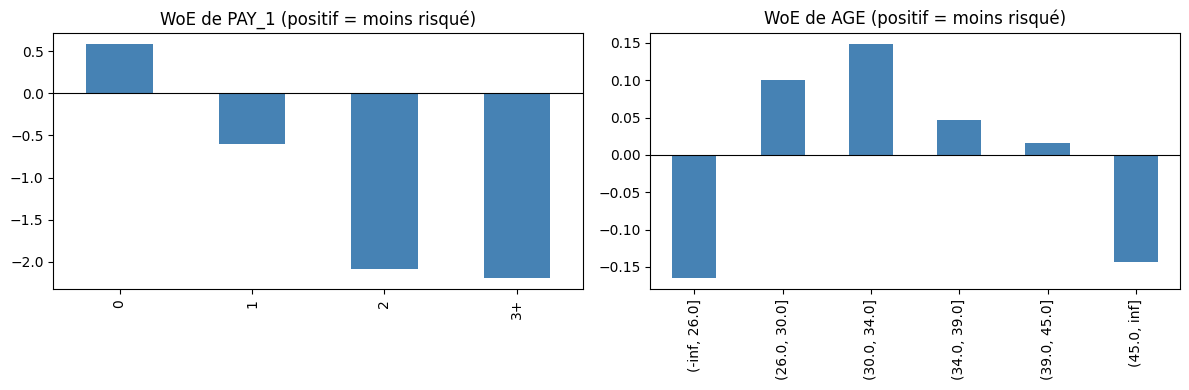

In [10]:
for var in ["PAY_1", "AGE"]:
    print(f"\n{var}")
    print(tables[var].to_string(formatters={"Taux de défaut": "{:.1%}".format,
                                            "WoE": "{:.3f}".format, "IV": "{:.3f}".format}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, var in zip(axes, ["PAY_1", "AGE"]):
    tables[var]["WoE"].plot.bar(ax=ax, color="steelblue")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"WoE de {var} (positif = moins risqué)")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("figures/woe.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Modèle de scoring : régression logistique et modèle challenger

In [11]:
# 1. On garde les variables utiles (IV >= 0,02)
candidates = synthese_iv[synthese_iv["IV"] >= 0.02].index.tolist()   # déjà triées par IV décroissant

# 2. On écarte les variables trop corrélées à une variable déjà retenue (de plus fort IV)
correlations = train_woe[candidates].corr()
retenues = []
for var in candidates:
    if all(abs(correlations.loc[var, r]) < 0.7 for r in retenues):
        retenues.append(var)

print("Variables candidates :", candidates)
print("Variables retenues   :", retenues)
correlations.round(2)

Variables candidates : ['PAY_1', 'nb_mois_retard', 'retard_max_6m', 'PAY_2', 'LIMIT_BAL', 'PAY_AMT1', 'taux_utilisation', 'EDUCATION']
Variables retenues   : ['PAY_1', 'retard_max_6m', 'PAY_2', 'LIMIT_BAL', 'PAY_AMT1', 'taux_utilisation', 'EDUCATION']


,PAY_1,nb_mois_retard,retard_max_6m,PAY_2,LIMIT_BAL,PAY_AMT1,taux_utilisation,EDUCATION
PAY_1,1.00,0.75,0.69,0.66,0.19,0.25,0.16,0.06
nb_mois_retard,0.75,1.00,0.95,0.75,0.26,0.28,0.15,0.09
retard_max_6m,0.69,0.95,1.00,0.67,0.27,0.26,0.14,0.09
PAY_2,0.66,0.75,0.67,1.00,0.22,0.33,0.12,0.09
LIMIT_BAL,0.19,0.26,0.27,0.22,1.00,0.23,0.32,0.18
PAY_AMT1,0.25,0.28,0.26,0.33,0.23,1.00,-0.06,0.04
taux_utilisation,0.16,0.15,0.14,0.12,0.32,-0.06,1.00,0.09
EDUCATION,0.06,0.09,0.09,0.09,0.18,0.04,0.09,1.00


In [12]:
import statsmodels.api as sm

# Avec le WoE, chaque coefficient doit être NÉGATIF (WoE élevé = classe peu risquée = PD plus faible).
# On retire une à une les variables de signe incohérent ou non significatives (p-value > 5 %).
while True:
    X_train = sm.add_constant(train_woe[retenues])
    logit = sm.Logit(train["defaut"], X_train).fit(disp=0)
    coefs, pvals = logit.params.drop("const"), logit.pvalues.drop("const")
    a_retirer = [v for v in retenues if coefs[v] > 0 or pvals[v] > 0.05]
    if not a_retirer:
        break
    pire = max(a_retirer, key=lambda v: pvals[v])
    print(f"Retrait de {pire} : coefficient {coefs[pire]:.3f}, p-value {pvals[pire]:.3f}")
    retenues.remove(pire)

X_test = sm.add_constant(test_woe[retenues])
pd_train_logit = logit.predict(X_train)
pd_test_logit = logit.predict(X_test)

print("\nModèle final :", retenues)
logit.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]]

Retrait de PAY_2 : coefficient -0.036, p-value 0.266

Modèle final : ['PAY_1', 'retard_max_6m', 'LIMIT_BAL', 'PAY_AMT1', 'taux_utilisation', 'EDUCATION']


,Coef.,Std.Err.,P>|z|
const,-1.255480,0.018839,0.000000e+00
PAY_1,-0.612950,0.024900,8.466652e-134
retard_max_6m,-0.484887,0.027199,4.353342e-71
LIMIT_BAL,-0.350570,0.050669,4.552615e-12
PAY_AMT1,-0.346245,0.049213,1.983480e-12
taux_utilisation,-0.251335,0.079876,1.652079e-03
EDUCATION,-0.382848,0.102888,1.984298e-04


In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier

features_brutes = [c for c in df.columns if c not in ["defaut", "SEX"]]   # variables brutes, sans le sexe
gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=4, random_state=42)
gbm.fit(train[features_brutes], train["defaut"])

pd_train_gbm = gbm.predict_proba(train[features_brutes])[:, 1]
pd_test_gbm = gbm.predict_proba(test[features_brutes])[:, 1]

In [14]:
from sklearn.metrics import roc_auc_score, roc_curve

def performance(y, score):
    auc = roc_auc_score(y, score)
    fpr, tpr, _ = roc_curve(y, score)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": (tpr - fpr).max()}

perf = pd.DataFrame({
    "Logistique – apprentissage": performance(train["defaut"], pd_train_logit),
    "Logistique – test": performance(test["defaut"], pd_test_logit),
    "Gradient boosting – apprentissage": performance(train["defaut"], pd_train_gbm),
    "Gradient boosting – test": performance(test["defaut"], pd_test_gbm),
}).T
perf.style.format("{:.1%}")

,AUC,Gini,KS
Logistique – apprentissage,76.6%,53.2%,41.6%
Logistique – test,75.6%,51.2%,39.6%
Gradient boosting – apprentissage,81.0%,61.9%,46.5%
Gradient boosting – test,78.0%,55.9%,42.4%


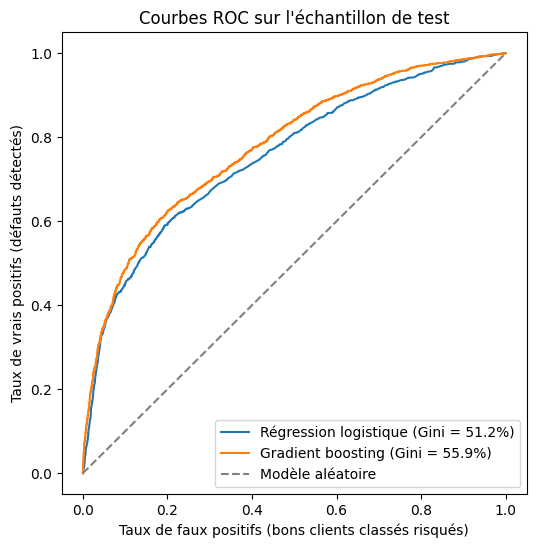

In [15]:
fig, ax = plt.subplots(figsize=(6, 6))
for nom, score in [("Régression logistique", pd_test_logit), ("Gradient boosting", pd_test_gbm)]:
    fpr, tpr, _ = roc_curve(test["defaut"], score)
    gini = 2 * roc_auc_score(test["defaut"], score) - 1
    ax.plot(fpr, tpr, label=f"{nom} (Gini = {gini:.1%})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Modèle aléatoire")
ax.set_xlabel("Taux de faux positifs (bons clients classés risqués)")
ax.set_ylabel("Taux de vrais positifs (défauts détectés)")
ax.set_title("Courbes ROC sur l'échantillon de test")
ax.legend(loc="lower right")
plt.savefig("figures/roc.png", dpi=150, bbox_inches="tight")
plt.show()

Après sélection (IV ≥ 0,02, corrélation < 0,7, significativité à 5 %), la régression logistique retient 6 variables, toutes de signe cohérent. Elle atteint un Gini de 51,2 % sur l’échantillon de test, avec un écart limité à l’apprentissage (2 points). Le gradient boosting obtient un Gini supérieur (55,9 %) mais surapprend davantage (6 points d’écart). La régression logistique est retenue comme modèle principal pour son explicabilité et sa stabilité, conformément aux pratiques réglementaires ; le gradient boosting sert de modèle challenger, et son écart de performance suggère des interactions non captées par le modèle linéaire.

## 4. Échelle de notation et calibration

In [16]:
# Échelle de notation : 7 classes définies par des seuils de PD
# Seuils adaptés au portefeuille : 7 classes d'effectifs comparables (quantiles de la PD sur l'apprentissage)
_, bornes_pd = pd.qcut(pd_train_logit, 7, retbins=True, duplicates="drop")
bornes_pd[0], bornes_pd[-1] = 0, 1
notes = ["A", "B", "C", "D", "E", "F", "G"][:len(bornes_pd) - 1]
print("Seuils de PD :", [f"{b:.1%}" for b in bornes_pd])

train_notes = pd.cut(pd_train_logit, bornes_pd, labels=notes, include_lowest=True)
test_notes = pd.cut(pd_test_logit, bornes_pd, labels=notes, include_lowest=True)

# Calibration : PD de chaque classe = taux de défaut observé sur l'apprentissage
calibration = train.groupby(train_notes, observed=False)["defaut"].agg(["count", "mean"])
calibration.columns = ["Clients (apprentissage)", "PD calibrée"]
pd_par_note = calibration["PD calibrée"]
calibration.style.format({"PD calibrée": "{:.1%}"})

Seuils de PD : ['0.0%', '9.0%', '10.4%', '12.2%', '14.2%', '24.6%', '45.9%', '100.0%']


,Clients (apprentissage),PD calibrée
A,3080,6.7%
B,2936,9.7%
C,2991,11.4%
D,3001,14.5%
E,2996,18.6%
F,3005,30.2%
G,2991,63.9%


In [17]:
from scipy.stats import binomtest

lignes = []
for note in notes:
    y_note = test.loc[test_notes == note, "defaut"]
    n, d = len(y_note), int(y_note.sum())
    p = pd_par_note[note]
    p_value = binomtest(d, n, p).pvalue if n > 0 else np.nan   # défauts observés compatibles avec la PD ?
    lignes.append({"Note": note, "Clients (test)": n, "Défauts": d, "PD calibrée": p,
                   "Taux observé (test)": d / n if n else np.nan, "p-value binomiale": p_value,
                   "Verdict (5 %)": "OK" if p_value >= 0.05 else "Écart significatif"})

validation = pd.DataFrame(lignes).set_index("Note")
print("Taux de défaut croissant de A à G :", validation["Taux observé (test)"].is_monotonic_increasing)
validation.style.format({"PD calibrée": "{:.1%}", "Taux observé (test)": "{:.1%}", "p-value binomiale": "{:.3f}"})

Taux de défaut croissant de A à G : True


,Clients (test),Défauts,PD calibrée,Taux observé (test),p-value binomiale,Verdict (5 %)
Note,,,,,,
A,1325,85,6.7%,6.4%,0.701,OK
B,1250,121,9.7%,9.7%,1.000,OK
C,1264,170,11.4%,13.4%,0.021,Écart significatif
D,1339,214,14.5%,16.0%,0.131,OK
E,1280,225,18.6%,17.6%,0.388,OK
F,1266,389,30.2%,30.7%,0.714,OK
G,1276,787,63.9%,61.7%,0.097,OK


In [18]:
repartition_train = train_notes.value_counts(normalize=True).reindex(notes)
repartition_test = test_notes.value_counts(normalize=True).reindex(notes)
psi = ((repartition_test - repartition_train) * np.log(repartition_test / repartition_train)).sum()
print(f"PSI apprentissage / test : {psi:.4f}")

PSI apprentissage / test : 0.0003


In [19]:
repartition_train = train_notes.value_counts(normalize=True).reindex(notes)
repartition_test = test_notes.value_counts(normalize=True).reindex(notes)
psi = ((repartition_test - repartition_train) * np.log(repartition_test / repartition_train)).sum()
print(f"PSI apprentissage / test : {psi:.4f}")

PSI apprentissage / test : 0.0003


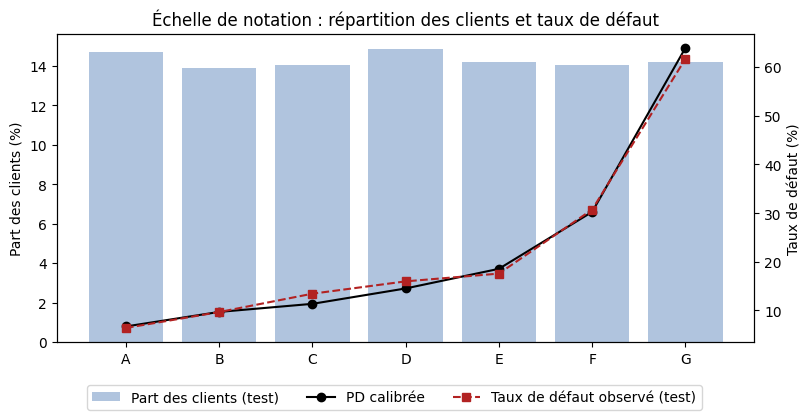

In [20]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(notes, repartition_test * 100, color="lightsteelblue", label="Part des clients (test)")
ax1.set_ylabel("Part des clients (%)")
ax2 = ax1.twinx()
ax2.plot(notes, validation["PD calibrée"] * 100, marker="o", color="black", label="PD calibrée")
ax2.plot(notes, validation["Taux observé (test)"] * 100, marker="s", linestyle="--", color="firebrick",
         label="Taux de défaut observé (test)")
ax2.set_ylabel("Taux de défaut (%)")
ax1.set_title("Échelle de notation : répartition des clients et taux de défaut")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=3)
plt.savefig("figures/echelle_notation.png", dpi=150, bbox_inches="tight")
plt.show()

Une première échelle à seuils fixes produisait une classe quasi vide (A, 9 clients) et une classe concentrant 36 % du portefeuille. Les seuils ont été redéfinis sur les quantiles de PD de l’échantillon d’apprentissage, ce qui donne 7 classes d’effectifs équilibrés (14 à 15 % chacune). Les PD calibrées vont de 6,7 % (A) à 63,9 % (G) et sont strictement croissantes, tout comme les taux observés sur le test. Six classes sur sept passent le test binomial ; l’écart sur la classe C (13,4 % observé contre 11,4 % prévu) reste compatible avec le risque de faux rejet lié aux tests multiples. Le PSI de 0,0003 confirme la stabilité entre apprentissage et test, mais une validation hors période (out-of-time) n’est pas possible faute de dimension temporelle dans les données.

## 5. Perte attendue et fonds propres réglementaires (IRB)

Hypothèses : LGD = 75 % (crédit revolving non garanti) ; EAD = montant utilisé + 50 % du montant non utilisé ;
PD = PD calibrée de la classe de notation. Montants en dollars taïwanais (NT$), sur le portefeuille de test.

In [21]:
from scipy.stats import norm

LGD = 0.75    # perte en cas de défaut
CCF = 0.50    # part du montant non utilisé tirée avant le défaut
R = 0.04      # corrélation réglementaire de Bâle pour les crédits revolving aux particuliers

portefeuille = test[["LIMIT_BAL", "BILL_AMT1"]].copy()
portefeuille["Note"] = test_notes
portefeuille["PD"] = test_notes.map(pd_par_note).astype(float)

utilise = portefeuille["BILL_AMT1"].clip(lower=0)
non_utilise = (portefeuille["LIMIT_BAL"] - utilise).clip(lower=0)
portefeuille["EAD"] = utilise + CCF * non_utilise
portefeuille["Perte attendue"] = portefeuille["PD"] * LGD * portefeuille["EAD"]

def k_irb(pd_, lgd=LGD, r=R):
    """Fonds propres IRB par unité d'exposition : perte d'une année à 1 sur 1 000, moins la perte attendue."""
    return lgd * (norm.cdf((norm.ppf(pd_) + np.sqrt(r) * norm.ppf(0.999)) / np.sqrt(1 - r)) - pd_)

portefeuille["Fonds propres"] = k_irb(portefeuille["PD"]) * portefeuille["EAD"]

In [22]:
par_note = portefeuille.groupby("Note", observed=False).agg(
    Clients=("PD", "size"), PD=("PD", "first"), EAD=("EAD", "sum"),
    **{"Perte attendue": ("Perte attendue", "sum"), "Fonds propres": ("Fonds propres", "sum")})
par_note["Perte attendue / EAD"] = par_note["Perte attendue"] / par_note["EAD"]
par_note["Fonds propres / EAD"] = par_note["Fonds propres"] / par_note["EAD"]

ead_total = portefeuille["EAD"].sum()
pa_totale = portefeuille["Perte attendue"].sum()
fp_total = portefeuille["Fonds propres"].sum()
print(f"Exposition totale (EAD)      : {ead_total / 1e6:,.0f} M NT$")
print(f"Perte attendue (provisions)  : {pa_totale / 1e6:,.0f} M NT$, soit {pa_totale / ead_total:.1%} de l'EAD")
print(f"Fonds propres IRB            : {fp_total / 1e6:,.0f} M NT$, soit {fp_total / ead_total:.1%} de l'EAD")
print(f"Actifs pondérés (RWA)        : {12.5 * fp_total / 1e6:,.0f} M NT$, soit {12.5 * fp_total / ead_total:.0%} de l'EAD")

par_note.style.format({"PD": "{:.1%}", "EAD": "{:,.0f}", "Perte attendue": "{:,.0f}", "Fonds propres": "{:,.0f}",
                       "Perte attendue / EAD": "{:.1%}", "Fonds propres / EAD": "{:.1%}"})

Exposition totale (EAD)      : 989 M NT$
Perte attendue (provisions)  : 132 M NT$, soit 13.3% de l'EAD
Fonds propres IRB            : 121 M NT$, soit 12.2% de l'EAD
Actifs pondérés (RWA)        : 1,514 M NT$, soit 153% de l'EAD


,Clients,PD,EAD,Perte attendue,Fonds propres,Perte attendue / EAD,Fonds propres / EAD
Note,,,,,,,
A,1325,6.7%,"281,624,848","14,195,538","24,850,752",5.0%,8.8%
B,1250,9.7%,"185,743,741","13,522,726","20,428,450",7.3%,11.0%
C,1264,11.4%,"145,244,747","12,382,952","17,444,545",8.5%,12.0%
D,1339,14.5%,"88,293,770","9,620,814","12,041,295",10.9%,13.6%
E,1280,18.6%,"90,254,426","12,562,115","13,769,005",13.9%,15.3%
F,1266,30.2%,"100,291,634","22,753,352","17,938,077",22.7%,17.9%
G,1276,63.9%,"97,049,572","46,529,283","14,614,449",47.9%,15.1%


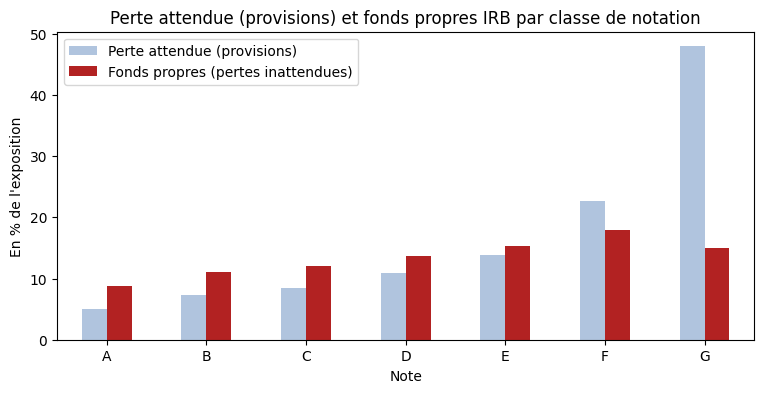

In [23]:
ax = (par_note[["Perte attendue / EAD", "Fonds propres / EAD"]] * 100).plot.bar(
    figsize=(9, 4), color=["lightsteelblue", "firebrick"], rot=0)
ax.set_ylabel("En % de l'exposition")
ax.set_title("Perte attendue (provisions) et fonds propres IRB par classe de notation")
ax.legend(["Perte attendue (provisions)", "Fonds propres (pertes inattendues)"])
plt.savefig("figures/perte_attendue_fonds_propres.png", dpi=150, bbox_inches="tight")
plt.show()

Sous les hypothèses retenues (LGD de 75 %, CCF de 50 %), la perte attendue atteint 13,3 % de l’exposition et les fonds propres IRB 12,2 %, soit une densité de RWA de 153 %, des niveaux élevés qui reflètent le contexte de crise des données. La perte attendue croît de 5,0 % (A) à 47,9 % (G), tandis que les fonds propres culminent en classe F (17,9 %) avant de redescendre en G (15,1 %) : pour les clients les plus risqués, la perte est majoritairement attendue et donc couverte par les provisions. La classe G concentre 35 % de la perte attendue pour 10 % de l’exposition. Limite : le défaut est observé à un mois, alors que la réglementation exige une PD à un an ; les montants illustrent la méthode plus qu’ils ne mesurent un risque réel.

## 6. Stress test macroéconomique

Modèle satellite reliant le taux de retard des cartes de crédit au taux de chômage (données FRED, États-Unis),
puis projection de la perte attendue et des fonds propres sous trois scénarios.

Période : 1991-01-01 → 2026-04-01 (142 trimestres)


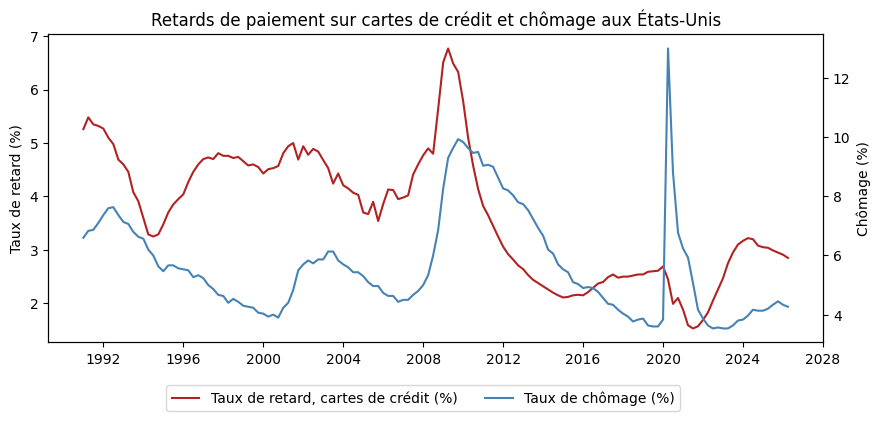

In [24]:
import statsmodels.api as sm

def charger_fred(serie):
    """Télécharge une série de la base FRED (Réserve fédérale de Saint-Louis) et la garde en local."""
    fichier = f"data/{serie}.csv"
    if not os.path.exists(fichier):
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={serie}"
        pd.read_csv(url).to_csv(fichier, index=False)
    return pd.read_csv(fichier, index_col=0, parse_dates=True, na_values=".").iloc[:, 0].dropna()

retards = charger_fred("DRCCLACBS")                       # taux de retard, cartes de crédit, banques américaines (trimestriel, %)
chomage = charger_fred("UNRATE").resample("QS").mean()    # taux de chômage (mensuel, moyenné par trimestre, %)

macro = pd.concat({"Taux de retard (%)": retards, "Chômage (%)": chomage}, axis=1, sort=True).dropna()
print(f"Période : {macro.index.min().date()} → {macro.index.max().date()} ({len(macro)} trimestres)")

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(macro.index, macro["Taux de retard (%)"], color="firebrick", label="Taux de retard, cartes de crédit (%)")
ax1.set_ylabel("Taux de retard (%)")
ax2 = ax1.twinx()
ax2.plot(macro.index, macro["Chômage (%)"], color="steelblue", label="Taux de chômage (%)")
ax2.set_ylabel("Chômage (%)")
ax1.set_title("Retards de paiement sur cartes de crédit et chômage aux États-Unis")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2)
plt.savefig("figures/macro.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
y = np.log(macro["Taux de retard (%)"] / (100 - macro["Taux de retard (%)"]))   # logit du taux de retard
X = sm.add_constant(macro["Chômage (%)"])
satellite = sm.OLS(y, X).fit()
beta = satellite.params["Chômage (%)"]

print(f"Coefficient β (effet d'1 point de chômage sur le logit du taux de retard) : {beta:.3f}")
print(f"p-value : {satellite.pvalues['Chômage (%)']:.4f}    R² : {satellite.rsquared:.2f}")

Coefficient β (effet d'1 point de chômage sur le logit du taux de retard) : 0.051
p-value : 0.0025    R² : 0.06


In [26]:
logit_retard = np.log(macro["Taux de retard (%)"] / (100 - macro["Taux de retard (%)"]))
chom = macro["Chômage (%)"]

covid = (macro.index >= "2020-04-01") & (macro.index <= "2021-12-31")
# Pour les variations sur un an, on exclut aussi 2022 : sa variation est calculée par rapport à l'année Covid
covid_var = (macro.index >= "2020-04-01") & (macro.index <= "2022-12-31")

def ajuster(y, x):
    return sm.OLS(y, sm.add_constant(x), missing="drop").fit()

modeles = {
    "1. Niveaux, toute la période": ajuster(logit_retard, chom),
    "2. Niveaux, hors Covid": ajuster(logit_retard[~covid], chom[~covid]),
    "3. Variations sur 4 trimestres, hors Covid": ajuster(logit_retard.diff(4)[~covid_var], chom.diff(4)[~covid_var]),
}

comparaison = pd.DataFrame({nom: {"β": m.params.iloc[1], "p-value": m.pvalues.iloc[1],
                                  "R²": m.rsquared, "Trimestres": int(m.nobs)}
                            for nom, m in modeles.items()}).T
comparaison.style.format({"β": "{:.3f}", "p-value": "{:.4f}", "R²": "{:.2f}", "Trimestres": "{:.0f}"})
beta = modeles["3. Variations sur 4 trimestres, hors Covid"].params.iloc[1]
print(f"β retenu : {beta:.3f}")

β retenu : 0.082


In [27]:
logit = lambda p: np.log(p / (1 - p))
inv_logit = lambda x: 1 / (1 + np.exp(-x))

scenarios = {"Central (chômage stable)": 0,
             "Adverse (+3 points de chômage)": 3,
             "Sévère (+5 points, type 2008-2009)": 5}

lignes, pd_stress_par_note = [], {}
ead = portefeuille["EAD"]
for nom, choc in scenarios.items():
    pd_stress = inv_logit(logit(portefeuille["PD"]) + beta * choc)    # choc appliqué à la PD de chaque client
    pd_stress_par_note[nom] = pd_stress.groupby(portefeuille["Note"], observed=False).first()
    pa = (pd_stress * LGD * ead).sum()
    fp = (k_irb(pd_stress) * ead).sum()
    lignes.append({"Scénario": nom, "PD moyenne (pondérée par l'EAD)": (pd_stress * ead).sum() / ead.sum(),
                   "Perte attendue (M NT$)": pa / 1e6, "Fonds propres (M NT$)": fp / 1e6,
                   "Total (M NT$)": (pa + fp) / 1e6})

stress = pd.DataFrame(lignes).set_index("Scénario")
stress["Hausse du total vs central"] = stress["Total (M NT$)"] / stress["Total (M NT$)"].iloc[0] - 1
stress.style.format({"PD moyenne (pondérée par l'EAD)": "{:.1%}", "Perte attendue (M NT$)": "{:,.1f}",
                     "Fonds propres (M NT$)": "{:,.1f}", "Total (M NT$)": "{:,.1f}",
                     "Hausse du total vs central": "{:+.0%}"})

,PD moyenne (pondérée par l'EAD),Perte attendue (M NT$),Fonds propres (M NT$),Total (M NT$),Hausse du total vs central
Scénario,,,,,
Central (chômage stable),17.7%,131.6,121.1,252.7,+0%
Adverse (+3 points de chômage),20.8%,154.5,130.7,285.2,+13%
"Sévère (+5 points, type 2008-2009)",23.1%,171.3,136.9,308.1,+22%


In [28]:
pd.DataFrame(pd_stress_par_note).style.format("{:.1%}")

,Central (chômage stable),Adverse (+3 points de chômage),"Sévère (+5 points, type 2008-2009)"
Note,,,
A,6.7%,8.4%,9.8%
B,9.7%,12.1%,13.9%
C,11.4%,14.1%,16.2%
D,14.5%,17.9%,20.4%
E,18.6%,22.6%,25.6%
F,30.2%,35.7%,39.5%
G,63.9%,69.4%,72.8%


Le modèle satellite initial (logit du taux de retard en niveau sur le chômage) est faible (R² de 0,06), car la relation est perturbée par la période Covid, où les aides publiques ont fait baisser les retards malgré la hausse du chômage, et par des changements structurels du marché du crédit. En excluant le Covid et en raisonnant en variations sur un an, le R² passe à 0,20 et la sensibilité au chômage de 0,051 à 0,082 : le modèle initial sous-estimait presque de moitié l’impact d’une crise. Sous le modèle retenu, le scénario sévère (+5 points de chômage) porte la PD moyenne de 17,7 % à 23,1 %, augmente la perte attendue de 30 % et les fonds propres de 13 %. En proportion, les meilleures classes se dégradent le plus (+46 % de PD pour la classe A, contre +14 % pour la classe G). Limites : modèle à une seule variable, données macroéconomiques américaines appliquées à un portefeuille taïwanais, et absence de migrations entre classes de notation.

## 7. Conclusions

### Synthèse

| Étape | Résultat clé |
|---|---|
| Données | 30 000 clients, taux de défaut de 22,1 % (crise du crédit à Taïwan, 2005) |
| Variables | Le comportement de paiement domine (IV de 0,88 pour le retard du dernier mois) ; l'âge est inutile (IV de 0,01) |
| Modèle | Régression logistique sur WoE, 6 variables, **Gini de 51,2 %** sur le test (challenger gradient boosting : 55,9 %) |
| Notation | 7 classes équilibrées, PD de 6,7 % (A) à 63,9 % (G), monotones et calibrées (6 tests binomiaux sur 7 validés, PSI de 0,0003) |
| Pertes et capital | Perte attendue de 13,3 % de l'exposition, fonds propres IRB de 12,2 % (densité de RWA de 153 %) |
| Stress test | Scénario sévère (+5 points de chômage) : perte attendue +30 %, fonds propres +13 % |

### Principaux enseignements

1. **Le comportement de paiement récent est le meilleur prédicteur du défaut** : un client avec deux mois de retard
   fait défaut 5 fois plus souvent qu'un client à jour.
2. **La régression logistique reste le bon choix pour un modèle réglementaire** : moins performante que le gradient boosting
   (−4,7 points de Gini), elle est explicable et plus stable. Le challenger signale des interactions non captées.
3. **Une échelle de notation doit être adaptée au portefeuille** : des seuils fixes produisaient une classe quasi vide
   et une classe concentrant 36 % des clients.
4. **Les fonds propres ne couvrent que la perte inattendue** : ils culminent pour la classe F puis baissent pour la classe G,
   dont les pertes sont majoritairement attendues et donc provisionnées.
5. **Un stress test ne vaut pas mieux que son modèle satellite** : le modèle initial (R² de 0,06) sous-estimait presque de
   moitié l'impact d'une crise. Corrigé (hors Covid, en variations), il porte le R² à 0,20.

### Limites

- **Horizon du défaut** : un mois dans les données, contre un an exigé par la réglementation (Bâle, IFRS 9).
- **LGD et EAD** : fixées par hypothèse (75 % et CCF de 50 %), faute de données de recouvrement.
- **Validation** : échantillon de test tiré au hasard, sans validation hors période (*out-of-time*).
- **Stress test** : modèle satellite à une variable, données macroéconomiques américaines, pas de migrations entre classes.
- **Contexte** : données de 2005, en période de crise, peu représentatives d'un portefeuille actuel.

### Pistes d'amélioration

- Enrichir le modèle logistique avec les historiques de montants sur six mois, pour réduire l'écart avec le challenger.
- Modéliser la LGD et l'EAD sur des données de recouvrement.
- Construire un modèle satellite multivarié (PIB, taux d'intérêt) avec des décalages temporels, et modéliser les migrations de notes.